In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

In [203]:
## SECURITY

def check_n_clients(n_clients):
    arr = np.asarray(n_clients)

    if not np.issubdtype(arr.dtype, np.integer):
        raise TypeError(f"n_clients must contain integers, got dtype {arr.dtype}")

    if np.any(arr < 0):
        raise ValueError("n_clients must be non-negative")

    return n_clients

def check_p_default(p_default):
    arr = np.asarray(p_default)

    if not (np.issubdtype(arr.dtype, np.integer) or np.issubdtype(arr.dtype, np.floating)):
        raise TypeError(f"p_default must be numeric, got dtype {arr.dtype}")

    if not np.all((arr >= 0) & (arr <= 1)):
        raise ValueError(f"p_default must be in [0, 1] and not NaN, got {p_default}")

    return p_default

In [205]:
def prob_at_least_one_default(n_clients: int, p_default: float) -> np.ndarray | float:

    n_clients = check_n_clients(n_clients)
    p_default = check_p_default(p_default)
    prob_not_default = 1-p_default
    all_not_default = prob_not_default ** n_clients
    at_least_one_default = 1 - all_not_default
    
    return at_least_one_default


def simulate_at_least_one_default(n_clients: int,p_default: float,
                                  n_sims: int = 100_000,seed: int | None = None) -> tuple[float, float]:
    
    n_clients = check_n_clients(n_clients)
    p_default = check_p_default(p_default)
    rng = np.random.default_rng(seed)
    u = rng.random(size = (n_sims,n_clients))
    defaults = u < p_default
    any_default = defaults.any(axis=1)
    estimate = any_default.mean()
    std_error = np.sqrt(estimate * (1-estimate)/n_sims)
    
    return float(estimate),float(std_error)
    

def plot_prob_vs_portfolio_size(max_clients: int, p_default:float):
    
    clients_nparray = np.array(list(range(1,max_clients+1)))
    defaults_prob = prob_at_least_one_default(clients_nparray,p_default)
    plt.plot(clients_nparray,defaults_prob)
    plt.show()
    

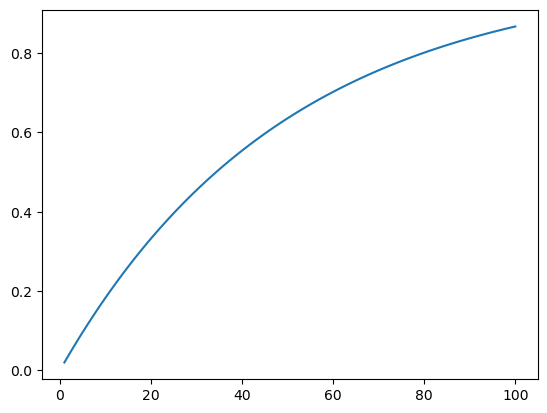

In [207]:
plot_prob_vs_portfolio_size(100,0.02)